Dataset shape: X=(569, 30), y=(569,)
Classes: [0 1] | Class distribution: [212 357]

=== 5-Fold Cross-Validation (mean ± std) ===
Accuracy  : 0.9737 ± 0.0166
Precision : 0.9683 ± 0.0290
Recall    : 0.9916 ± 0.0112
F1        : 0.9794 ± 0.0127
ROC-AUC   : 0.9953 ± 0.0053

=== Hold-out Test Set Metrics ===
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1       : 0.9861
ROC-AUC  : 0.9954

=== Confusion Matrix ===
                  Pred malignant  Pred benign
Actual malignant              41            1
Actual benign                  1           71

MSE (on 0/1 labels): 0.0175
R²  (on 0/1 labels): 0.9246


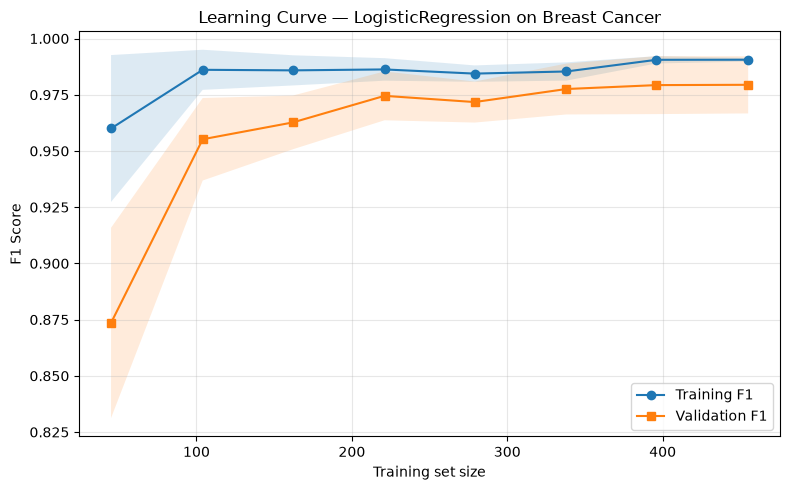

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    cross_val_score, StratifiedKFold, learning_curve,
    train_test_split
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    mean_squared_error, r2_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


data = load_breast_cancer()
X, y = data.data, data.target
print(f"Dataset shape: X={X.shape}, y={y.shape}")
print(f"Classes: {np.unique(y)} | Class distribution: {np.bincount(y)}")


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_f1      = cross_val_score(model, X, y, cv=cv, scoring="f1")
cv_acc     = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
cv_prec    = cross_val_score(model, X, y, cv=cv, scoring="precision")
cv_recall  = cross_val_score(model, X, y, cv=cv, scoring="recall")
cv_roc_auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")

print("\n=== 5-Fold Cross-Validation (mean ± std) ===")
for name, s in [("Accuracy", cv_acc), ("Precision", cv_prec),
                ("Recall", cv_recall), ("F1", cv_f1), ("ROC-AUC", cv_roc_auc)]:
    print(f"{name:<10}: {s.mean():.4f} ± {s.std():.4f}")


model.fit(X_train, y_train)

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("\n=== Hold-out Test Set Metrics ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")


cm = confusion_matrix(y_test, y_pred)
print("\n=== Confusion Matrix ===")
print(pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in data.target_names],
    columns=[f"Pred {c}" for c in data.target_names],
))


mse = mean_squared_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)
print(f"\nMSE (on 0/1 labels): {mse:.4f}")
print(f"R²  (on 0/1 labels): {r2:.4f}")


train_sizes, train_scores, val_scores = learning_curve(
    model, X, y, cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="f1", n_jobs=-1, random_state=42,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", label="Training F1")
plt.fill_between(train_sizes, train_mean - train_std,
                 train_mean + train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, "s-", label="Validation F1")
plt.fill_between(train_sizes, val_mean - val_std,
                 val_mean + val_std, alpha=0.15)
plt.xlabel("Training set size")
plt.ylabel("F1 Score")
plt.title("Learning Curve — LogisticRegression on Breast Cancer")
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()